<div style="background:linear-gradient(135deg,#0f3d6e,#1f6fb2);color:#ffffff;padding:22px 26px;border-radius:8px;">
<div style="font-size:13px;letter-spacing:1.5px;text-transform:uppercase;opacity:.85;">INF432 · Segundo Examen</div>
<div style="font-size:28px;font-weight:700;margin:6px 0 4px 0;color:#ffffff;">Proyecto de minería de datos · [Título del proyecto]</div>
<div style="font-size:15px;opacity:.95;color:#ffffff;">Plantilla de código del Segundo Examen · Grupo __</div>
</div>

**Archivo:** INF432_SE2_Plantilla_Codigo.ipynb  |  **MATERIA:** INF 432 - Soporte para la toma de decisiones

<div style="background:#e9f7ef;border-left:6px solid #2e8b57;padding:12px 16px;border-radius:4px;color:#1f2937;"><b style="color:#2e8b57;">Cómo usar esta plantilla</b><br><ul>
<li>Pueden dividirla en varios notebooks (<code>00_Datos.ipynb</code>, <code>01_Area_....ipynb</code>...) o mantener uno solo.</li>
<li>Cada celda de código debe ir acompañada de una celda de texto que explique <b>qué</b> hacen y <b>por qué</b>, como en las lecciones del curso.</li>
<li>Antes de entregar: <b>Kernel &gt; Restart &amp; Run All</b>. El notebook debe ejecutarse completo y sin errores.</li>
<li>Borren los recuadros de instrucciones y las celdas <code># TODO</code> que no usen.</li>
</ul></div>

## Ficha del proyecto

| Campo | Completar |
|---|---|
| Grupo | RetailAnalytics |
| Integrantes | 1. Banegas Bruno Diego Fernando    2. Hernandez Lijeron Roly    3. Huanca Silvestre Grover |
| Organización o escenario |Cadena minorista (supuesta) que vende vinos, carnes, frutas, pescados, dulces y productos premium por tienda física, web y catálogo |
| Área 1 y pregunta de negocio | **A1 Campañas de marketing:** ¿a qué clientes dirigir la próxima campaña para lograr más aceptaciones con menos llamadas?|
| Área 2 y pregunta de negocio | **A2 Segmentación de mercado:** ¿qué grupos de clientes existen según su perfil y lo que compran, y qué estrategia merece cada uno?|
| Área 3 y pregunta de negocio | **A3 Patrones de compra:** ¿qué patrones de compra (RFM, canal, descuentos) existen y por qué canal llegar a cada uno? |
| Conjunto(s) de datos (con enlace) | Customer Personality Analysis (Kaggle): https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis · 2240 clientes, 29 columnas · clase: `Response`|

# 1. ENTENDIMIENTO DEL NEGOCIO

La empresa gasta en campañas y promociones de la misma forma para todos sus clientes, sin saber quién responde ni por qué canal compra cada uno. Este proyecto apoya tres decisiones:
- **Área 1, Campañas (supervisada):** el gerente de marketing decide a quién llamar. *Criterio de éxito:* detectar al menos el 60 % de los clientes que aceptarán, con una precisión mayor al 15 % actual.
- **Área 2, Segmentación (no supervisada):** el gerente comercial decide qué ofrecer a cada grupo. *Criterio de éxito:* de 3 a 6 grupos con silueta > 0.25 y perfiles distintos con nombre comercial.
- **Área 3, Patrones de compra (no supervisada):** el jefe de canales decide en qué canal invertir para cada patrón. *Criterio de éxito:* de 3 a 5 patrones con silueta > 0.25 y diferencias claras en RFM o canal.

# 2. IMPORTAR LAS LIBRERÍAS

En esta fase vamos a hacer 3 cosas:
1. Importar las librerías para manejar datos (pandas, numpy) y para hacer gráficas (matplotlib, seaborn).
2. Fijar una semilla (`SEMILLA = 1`) para que los resultados sean siempre los mismos al volver a ejecutar.
3. Mostrar las versiones de las librerías, que se copiarán al `requirements.txt`.
Las librerías de scikit-learn (PCA, LDA, kNN, Naive Bayes, árbol, k-means, DBSCAN) se importan en la sección de cada área, justo donde se usan.


In [1]:

import os                        # Para rutas y carpetas
import pandas as pd              # Para manejar dataframes (Tablas)
import numpy as np               # Para cálculos numéricos
import matplotlib.pyplot as plt  # Para hacer gráficas
import seaborn as sns            # Para gráficas estadísticas
from IPython.display import display # Para visualización enriquecida de tablas

SEMILLA = 1                     # Semilla Fija  para q los resultados siempre salgan yguales 


In [2]:
# Versiones usadas (cópienlas al README.md y al requirements.txt)
import sklearn, scipy
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__)
print("seaborn     ", sns.__version__)

print("numpy       ", np.__version__); print("matplotlib  ", plt.matplotlib.__version__)

pandas       3.0.0
scikit-learn 1.8.0
scipy        1.17.0
seaborn      0.13.2
numpy        2.4.1
matplotlib   3.10.8


# 3. ENTENDIMIENTO DE LOS DATOS

## 3.1 Cargar los datos

Guarden los archivos originales en `data/raw/` y usen **rutas relativas**. Indiquen la fuente y la licencia en una celda de texto.

In [3]:
df = pd.read_csv('data/raw/marketing_campaign.csv', sep='\t')  # Lee el archivo original; las columnas vienen separadas por tabulaciones
print("Filas y columnas:", df.shape)                           # Muestra cuántas filas (clientes) y columnas (variables) hay
df.head()                                                      # Muestra los primeros 5 clientes

Filas y columnas: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


**Diccionario de datos**

| Grupo | Variable | Tipo | Descripción |
|---|---|---|---|
| Cliente | ID | Identificador | Código único del cliente (no se usa para modelar) |
| Cliente | Year_Birth | Numérica | Año de nacimiento |
| Cliente | Education | Categórica | Nivel educativo (Basic, 2n Cycle, Graduation, Master, PhD) |
| Cliente | Marital_Status | Categórica | Estado civil |
| Cliente | Income | Numérica | Ingreso anual del hogar |
| Cliente | Kidhome | Numérica | Número de niños pequeños en el hogar |
| Cliente | Teenhome | Numérica | Número de adolescentes en el hogar |
| Cliente | Dt_Customer | Fecha | Fecha de registro del cliente en la empresa |
| Cliente | Recency | Numérica | Días desde la última compra |
| Cliente | Complain | Binaria | 1 si se quejó en los últimos 2 años |
| Productos | MntWines | Numérica | Monto gastado en vinos (últimos 2 años) |
| Productos | MntFruits | Numérica | Monto gastado en frutas |
| Productos | MntMeatProducts | Numérica | Monto gastado en carnes |
| Productos | MntFishProducts | Numérica | Monto gastado en pescado |
| Productos | MntSweetProducts | Numérica | Monto gastado en dulces |
| Productos | MntGoldProds | Numérica | Monto gastado en productos de oro/premium |
| Promoción | NumDealsPurchases | Numérica | Compras hechas con descuento |
| Promoción | AcceptedCmp1 a AcceptedCmp5 | Binaria | 1 si aceptó la oferta de la campaña 1, 2, 3, 4 o 5 |
| Promoción | **Response** | Binaria | **Clase (y):** 1 si aceptó la oferta de la última campaña |
| Canal | NumWebPurchases | Numérica | Compras por la página web |
| Canal | NumCatalogPurchases | Numérica | Compras por catálogo |
| Canal | NumStorePurchases | Numérica | Compras en tienda física |
| Canal | NumWebVisitsMonth | Numérica | Visitas a la web en el último mes |
| Otras | Z_CostContact, Z_Revenue | Constante | Sin documentación y con el mismo valor en todas las filas; se eliminan |

## 3.2 Explorar los datos

*Estadística descriptiva (`df.describe()`, `df.info()`), distribución de la variable de clase (`sns.countplot`), histogramas y `PairGrid` (lección 2.2). Después de cada gráfico, escriban qué observan.*

En esta fase vamos a hacer 2 cosas:

Ver el tipo de dato de cada columna y cuántos valores no nulos tiene.
Ver la estadística descriptiva de las variables numéricas.

In [4]:
df.info()             # Muestra cada columna, su tipo de dato y cuántos valores no nulos tiene

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [5]:
df.describe().T       # Estadística descriptiva (media, mínimo, máximo, cuartiles); .T la voltea para leerla mejor

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


¿Qué observamos?

El conjunto tiene 2240 clientes y 29 variables: 25 enteras, 1 decimal y 3 de texto (Education, Marital_Status, Dt_Customer).
Income tiene 24 valores faltantes.
Dt_Customer es una fecha guardada como texto; habrá que convertirla.
Z_CostContact y Z_Revenue son constantes y no aportan información.
Hay atípicos: años de nacimiento anteriores a 1900 e ingresos extremos (666 666).
Los gastos (Mnt...) son muy asimétricos: la media es mucho mayor que la mediana. Pocos clientes gastan muchísimo.

## 3.3 Calidad de los datos

*Faltantes (`df.isna().sum()`), duplicados (`df.duplicated().sum()`), valores atípicos y errores.*

En esta fase vamos a hacer 3 cosas:

Contar faltantes y filas duplicadas.
Revisar los valores de las variables categóricas.
Buscar valores atípicos con diagramas de caja

# Celda 1, faltantes y duplicados

In [6]:
faltantes = df.isna().sum()                                            # Cuenta los valores faltantes por columna
print("Columnas con faltantes:\n", faltantes[faltantes > 0])          # Muestra solo las columnas que tienen faltantes
print("Filas duplicadas:", df.duplicated().sum())                      # Filas idénticas en todas las columnas
print("Duplicadas sin contar el ID:", df.drop('ID', axis=1).duplicated().sum())  # Mismo cliente registrado con otro ID

Columnas con faltantes:
 Income    24
dtype: int64
Filas duplicadas: 0
Duplicadas sin contar el ID: 182


# Celda 2, categóricas:

In [7]:
print(df['Education'].value_counts())        # Cuántos clientes hay en cada nivel educativo
print(df['Marital_Status'].value_counts())   # Cuántos clientes hay en cada estado civil

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


# Celda 3, atípicos:

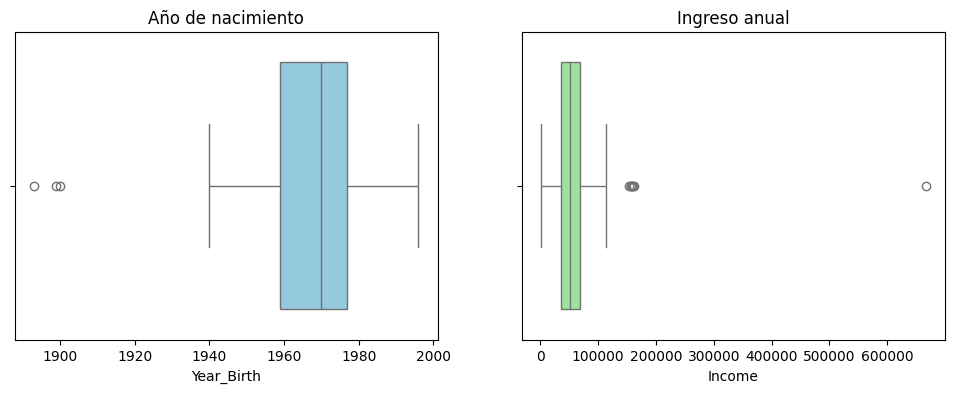

,ID,Year_Birth,Income
192,7829,1900,36640.0
239,11004,1893,60182.0
339,1150,1899,83532.0
2233,9432,1977,666666.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))                     # Una figura con 2 gráficas lado a lado
sns.boxplot(x=df['Year_Birth'], ax=axes[0], color='skyblue')        # Caja del año de nacimiento
axes[0].set_title('Año de nacimiento')                               # Título de la primera gráfica
sns.boxplot(x=df['Income'], ax=axes[1], color='lightgreen')         # Caja del ingreso
axes[1].set_title('Ingreso anual')                                   # Título de la segunda gráfica
plt.show()                                                           # Muestra las gráficas

df[(df['Year_Birth'] <= 1900) | (df['Income'] > 200000)][['ID', 'Year_Birth', 'Income']]  # Muestra los clientes sospechosos

¿Qué observamos?

Faltantes: solo Income tiene 24 faltantes (1.1 % de los clientes).
Duplicados: no hay filas idénticas, pero sin contar el ID aparecen 182 clientes repetidos (8 %). Es el mismo cliente registrado dos veces con distinto código.
Categóricas: Marital_Status tiene valores sin sentido: Absurd (2) y YOLO (2), que son errores de captura, y Alone (3), que significa lo mismo que Single. En Education, 2n Cycle equivale a una maestría.
Atípicos: 3 clientes nacieron en 1900 o antes (más de 120 años), lo cual es imposible, y un cliente declara un ingreso de 666 666, muy lejos del resto. Los ingresos de entre 150 000 y 160 000 son altos pero creíbles.


# 4. PREPARACIÓN DE LOS DATOS

*Limpieza, variables derivadas (por ejemplo, RFM), codificación de categóricas (`pd.get_dummies`), estandarización (`StandardScaler`) y división entrenamiento/prueba (`train_test_split` con `test_size=0.30` y `random_state=SEMILLA`). Guarden los datos preparados en `data/processed/`.*

4.1 Limpieza
En esta fase vamos a aplicar las decisiones de la sección 3.3:

Eliminar las columnas constantes.
Eliminar los faltantes y los clientes duplicados.
Corregir los estados civiles.
Eliminar las edades imposibles y el ingreso extremo.

In [9]:
df_limpio = df.copy()                                                          # Copia para no modificar los datos originales
df_limpio['Marital_Status'] = df_limpio['Marital_Status'].replace('Alone', 'Single')  # Alone significa lo mismo que Single
df_limpio = df_limpio.drop(['Z_CostContact', 'Z_Revenue'], axis=1) \
                     .dropna()                                                 # Quita las 2 columnas constantes y los 24 sin ingreso
df_limpio = df_limpio.drop_duplicates(subset=df_limpio.columns.drop('ID'))     # Quita clientes repetidos ignorando el ID
df_limpio = df_limpio[~df_limpio['Marital_Status'].isin(['Absurd', 'YOLO'])]   # Quita estados civiles sin sentido
df_limpio = df_limpio[(df_limpio['Year_Birth'] > 1900) & (df_limpio['Income'] < 600000)]  # Quita edades imposibles e ingreso extremo
df_limpio = df_limpio.reset_index(drop=True)                                   # Renumera las filas desde 0

print("Antes de limpiar :", df.shape)                                          # Tamaño original
print("Después de limpiar:", df_limpio.shape)                                  # Tamaño final
print(df_limpio['Marital_Status'].value_counts())                              # Comprueba que ya no hay valores raros

Antes de limpiar : (2240, 29)
Después de limpiar: (2025, 27)
Marital_Status
Married     788
Together    512
Single      440
Divorced    215
Widow        70
Name: count, dtype: int64


¿Qué observamos? Pasamos de 2240 a 2025 clientes: eliminamos 215 filas (9.6 %), casi todas duplicadas. Seguimos muy por encima del mínimo de 400 casos.

# variables derivadas (4.2)

4.2 Variables derivadas
En esta fase vamos a crear 7 variables nuevas que resumen mejor a cada cliente y que son más fáciles de explicar a la gerencia.

In [10]:
df_limpio['Dt_Customer'] = pd.to_datetime(df_limpio['Dt_Customer'], format='%d-%m-%Y')  # Convierte el texto a fecha real
fecha_ref = df_limpio['Dt_Customer'].max()                                    # Fecha más reciente del conjunto (referencia)

productos = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
canales   = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
campanas  = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']

df_limpio['Edad']          = fecha_ref.year - df_limpio['Year_Birth']                 # Edad del cliente en el año de referencia
df_limpio['Hijos']         = df_limpio['Kidhome'] + df_limpio['Teenhome']             # Total de hijos en casa
df_limpio['En_Pareja']     = df_limpio['Marital_Status'].isin(['Married', 'Together']).astype(int)  # 1 si vive en pareja
df_limpio['Gasto_Total']   = df_limpio[productos].sum(axis=1)                         # Monetario (M): gasto total en 2 años
df_limpio['Compras_Total'] = df_limpio[canales].sum(axis=1)                           # Frecuencia (F): número total de compras
df_limpio['Antiguedad']    = (fecha_ref - df_limpio['Dt_Customer']).dt.days           # Días que lleva como cliente
df_limpio['Campanas_Acep'] = df_limpio[campanas].sum(axis=1)                          # Cuántas campañas anteriores aceptó

df_limpio[['Edad', 'Hijos', 'En_Pareja', 'Gasto_Total', 'Compras_Total', 'Antiguedad', 'Campanas_Acep']].describe().T  # Revisa las nuevas variables

,count,mean,std,min,25%,50%,75%,max
Edad,2025.0,45.115062,11.656145,18.0,37.0,44.0,55.0,74.0
Hijos,2025.0,0.952593,0.746351,0.0,0.0,1.0,1.0,3.0
En_Pareja,2025.0,0.641975,0.479538,0.0,0.0,1.0,1.0,1.0
Gasto_Total,2025.0,607.708642,603.458917,5.0,69.0,397.0,1048.0,2525.0
Compras_Total,2025.0,12.559012,7.192689,0.0,6.0,12.0,18.0,32.0
Antiguedad,2025.0,352.470123,202.443561,0.0,178.0,352.0,528.0,699.0
Campanas_Acep,2025.0,0.300741,0.679255,0.0,0.0,0.0,0.0,4.0


¿Qué observamos?

Las edades van de 18 a 74 años (promedio de 45): ya no hay edades imposibles.
En Gasto_Total la mediana es 397 y la media 608: pocos clientes gastan mucho. Eso anticipa que habrá un grupo de “clientes de alto valor”.
La antigüedad va de 0 a 699 días: todos se registraron en un periodo de unos 2 años.
La mayoría no aceptó ninguna campaña anterior (la mediana de Campanas_Acep es 0).

# gráficos de exploración (4.3)

Celda A, la variable de clase:

Response
0    0.846914
1    0.153086
Name: proportion, dtype: float64


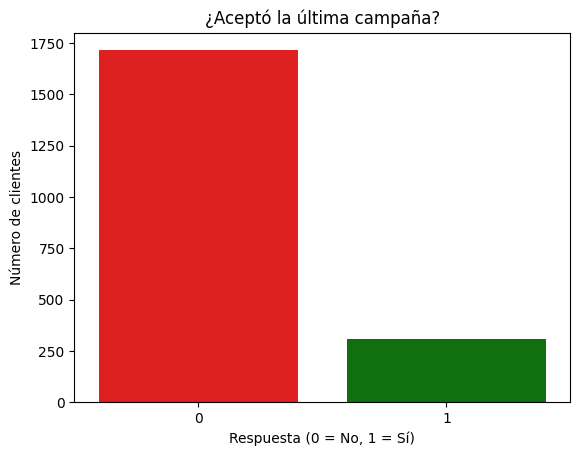

In [11]:
sns.countplot(x='Response', data=df_limpio, hue='Response', palette=['red', 'green'], legend=False)  # Cuántos aceptaron (1) y no (0)
plt.title('¿Aceptó la última campaña?')                         # Título
plt.xlabel('Respuesta (0 = No, 1 = Sí)')                        # Eje X
plt.ylabel('Número de clientes')                                # Eje Y
plt.show()
print(df_limpio['Response'].value_counts(normalize=True))      # Proporción de cada clase

¿Qué observamos? El 84.7 % de los clientes no aceptó la última campaña y solo el 15.3 % sí. Las clases están desbalanceadas: en el Área 1 no basta con la exactitud, hay que revisar cuántos aceptantes detecta el modelo

Celda B, histogramas:

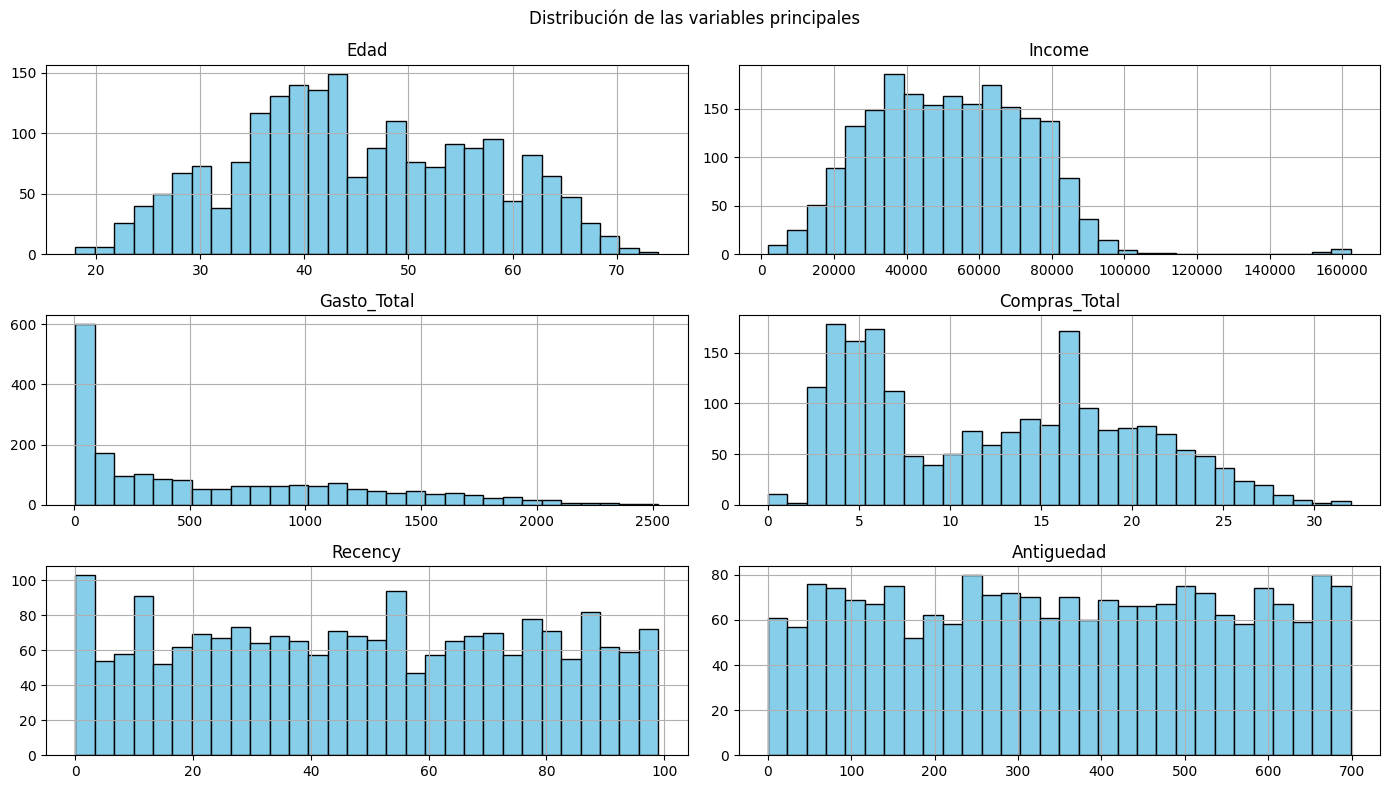

In [12]:
df_limpio[['Edad', 'Income', 'Gasto_Total', 'Compras_Total', 'Recency', 'Antiguedad']] \
    .hist(bins=30, figsize=(14, 8), color='skyblue', edgecolor='black')  # Un histograma por variable
plt.suptitle('Distribución de las variables principales')                # Título general
plt.tight_layout()                                                       # Acomoda para que no se encimen
plt.show()

¿Qué observamos?

Edad e Income tienen forma de campana; la mayoría gana entre 20 000 y 90 000.
Gasto_Total está muy cargado a la izquierda: muchos clientes gastan casi nada y pocos gastan mucho.
Compras_Total tiene dos picos (cerca de 5 y cerca de 15-20). Esto sugiere que hay dos tipos de compradores, ocasionales y frecuentes, y es una pista para el agrupamiento.
Recency y Antiguedad son casi uniformes: hay clientes de todos los niveles.

Celda C, PairGrid (como en la lección 2.2):

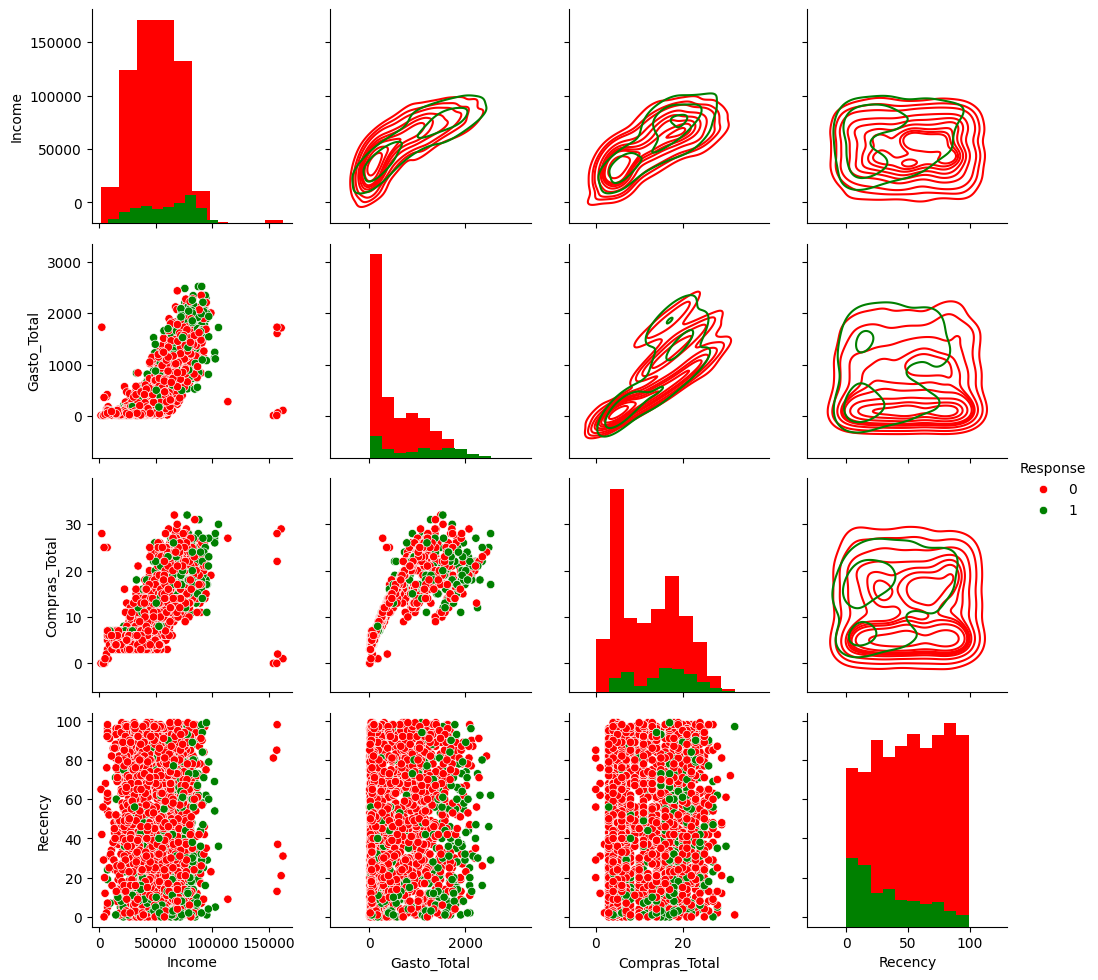

In [13]:
g = sns.PairGrid(df_limpio, vars=['Income', 'Gasto_Total', 'Compras_Total', 'Recency'],
                 hue='Response', diag_sharey=False, palette=['red', 'green'])  # Cruza 4 variables, coloreadas por la clase
g.map_diag(plt.hist)          # Diagonal: histograma de cada variable
g.map_upper(sns.kdeplot)      # Arriba: curvas de densidad
g.map_lower(sns.scatterplot)  # Abajo: dispersión punto por punto
g.add_legend()                # Leyenda
plt.show()

¿Qué observamos?

A mayor ingreso, mayor gasto y más compras: hay una relación positiva fuerte.
Los que aceptaron (verde) se concentran en Recency baja. Los clientes que compraron hace poco responden más a las campañas, así que será una variable clave del Área 1.
Los verdes también aparecen más en gasto alto.
Hay unos pocos clientes con ingreso cercano a 150 000 pero gasto casi nulo: un perfil atípico que vale la pena mencionar.

# guardar los datos limpios (4.4)

In [14]:
os.makedirs('data/processed', exist_ok=True)                                  # Crea la carpeta si no existe
df_limpio.to_csv('data/processed/clientes_limpio.csv', sep=',', index=False)  # Guarda los datos limpios sin el índice
print("Datos guardados:", df_limpio.shape)                                    # Confirma el tamaño guardado

Datos guardados: (2025, 34)


---
# 4.5 Resumen de la Preparación y Próximos Pasos

El conjunto de datos depurado se ha guardado exitosamente en `data/processed/clientes_limpio.csv` con **2,025 clientes y 34 variables**.

Este archivo procesado sirve como entrada directa para los tres cuadernos de modelado especializados:
1. **`01_Area_Campanas.ipynb`**: Área 1 (A1 - Supervisado) · Optimización de llamadas de campañas (kNN, Naive Bayes, Árbol, PCA vs LDA).
2. **`02_Area_Segmentacion.ipynb`**: Área 2 (A2 - No Supervisado) · Segmentación de mercado (k-means, jerárquico, PCA 2D y perfiles).
3. **`03_Area_Patrones.ipynb`**: Área 3 (A3 - No Supervisado) · Patrones de compra multicanal (RFM, k-means, DBSCAN y evaluación global).
